In [1]:
import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

df = pd.read_csv("uber.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [4]:
df = df.dropna(subset=['dropoff_longitude', 'dropoff_latitude'])

In [5]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [6]:
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
df['hour_of_day'] = df['pickup_datetime'].dt.hour
df['month'] = df['pickup_datetime'].dt.month

In [7]:
df = df.drop(['Unnamed: 0', 'key'], axis=1)

In [8]:
import numpy as np

def haversine(lon1, lat1, lon2, lat2):
    R = 6371  
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    distance = R * c
    return distance

df['distance_km'] = haversine(df['pickup_longitude'], df['pickup_latitude'],
                              df['dropoff_longitude'], df['dropoff_latitude'])


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[ns, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
 7   day_of_week        199999 non-null  int32              
 8   hour_of_day        199999 non-null  int32              
 9   month              199999 non-null  int32              
 10  distance_km        199999 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(6), int32(3), int64(1)
memory usage: 16.0 MB


In [10]:
import numpy as np

def capOutliers(df, columns):
    df_capped = df.copy()  

    for column in columns:
        lower_bound = df_capped[column].quantile(0.01)  
        upper_bound = df_capped[column].quantile(0.99)  
        
        df_capped[column] = np.where(df_capped[column] < lower_bound, lower_bound, df_capped[column])
        df_capped[column] = np.where(df_capped[column] > upper_bound, upper_bound, df_capped[column])
    
    return df_capped

columns_to_cap = ["fare_amount", "passenger_count", "distance_km"]
df_cleaned = capOutliers(df, columns_to_cap)

print(f"Original data shape: {df.shape}")
print(f"Capped data shape: {df_cleaned.shape}")

Original data shape: (199999, 11)
Capped data shape: (199999, 11)


In [11]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[ns, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  float64            
 7   day_of_week        199999 non-null  int32              
 8   hour_of_day        199999 non-null  int32              
 9   month              199999 non-null  int32              
 10  distance_km        199999 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(7), int32(3)
memory usage: 16.0 MB


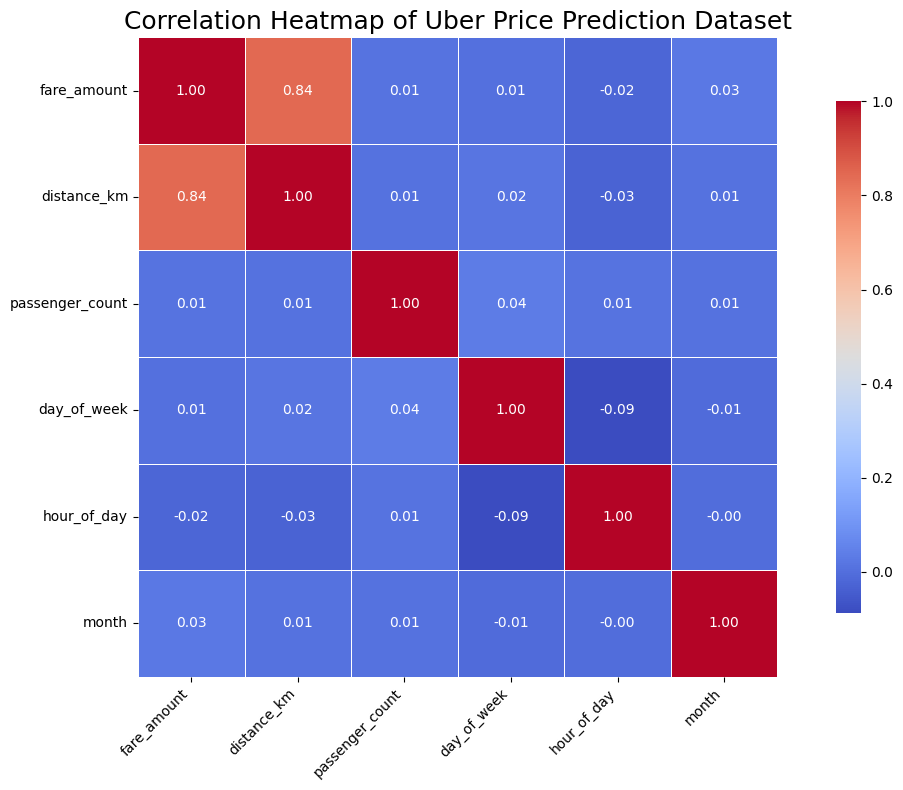

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

df_test = df_cleaned[["fare_amount",'distance_km', 'passenger_count', 'day_of_week', 'hour_of_day', 'month']]
correlation_matrix = df_test.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix, 
            annot=True,        
            fmt=".2f",        
            cmap="coolwarm",  
            square=True,      
            linewidths=0.5,  
            cbar_kws={"shrink": .8},  
            mask=None)        

plt.title('Correlation Heatmap of Uber Price Prediction Dataset', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()  

plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X = df_cleaned[['distance_km', 'passenger_count', 'day_of_week', 'hour_of_day', 'month']]
y = df_cleaned['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [15]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred = lin_reg.predict(X_test)

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'Linear Regression RMSE: {rmse}')
print(f'Linear Regression R²: {r2}')

Linear Regression RMSE: 5.0093923045340825
Linear Regression R²: 0.694543624749993


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

In [19]:
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f'Random Forest RMSE: {rmse_rf}')
print(f'Random Forest R²: {r2_rf}')

Random Forest RMSE: 4.89074794162698
Random Forest R²: 0.7088413701984508
